# Distributed SPO-GBT on Vertex AI: weak and strong scaling

Companion of `Distributed_SPO_GBT.ipynb` (same images, same `train.py`, run that notebook's setup cells once first).
Synthetic **trunk** data (two Gaussian classes at ±1/√(j+1) on the first 256 columns, the recipe of
`MakeTrunkDataset` in `examples/train_oblique_forest.cc`; numpy RNG, so not bit-identical to the C++ stream), 32 columns.

| Experiment | rows | workers |
|---|---|---|
| Weak scaling (100k rows per worker) | 100k, 200k, 400k, 800k, 1.6M | 1, 2, 4, 8, 16 |
| Strong scaling | 1.6M | 1, 2, 4, 8, 16 |

Both arms, 50 trees, one manager + `w` workers of the same machine type, GRPC. AA-GBT: YDF defaults. SPO-GBT: the
paper's Table-9 arm — **P = F projections per node in total**, split across the workers (the in-worker kernel samples
`ceil(F**exponent)` projections per worker from its own F/W columns, so the exponent is set per `w` to give F/w),
density 1.5, binary weights; everything else YDF defaults. Not the library default projection count: that is
P = F² = 1024 per worker per node, each an exact sort over the node's rows, and it took ~27 min per tree at 16 workers
(run 20261015T035046Z, cancelled after tree 1). Jobs run concurrently under the project's Vertex training vCPU quota.

**Timing** (all on the manager's clock, written to `eval.json` by `train.py`): `train_seconds` = wall around
`learner.train`; `setup_s` = start → "Start tree training" (dataset-cache creation + workers loading their columns);
`tree_training_s` = "Start tree training" → "Training done" — the number the scaling plots use.

In [1]:
import datetime, hashlib, json, math, os, subprocess, time

PROJECT = "ydf-distributed-spo-gbt"
REGION = "us-east1"
BUCKET = "ariel_ydf_bucket"
YDF_COMMIT = "cb81b53da5e6783f317ea95f678fdb06b41d6f96"
AR = f"{REGION}-docker.pkg.dev/{PROJECT}/ydf-repo"
WHEEL_IMAGE = f"{AR}/ydf-wheel:{YDF_COMMIT[:8]}"
BUILD_FILES = ["vertex_build/Dockerfile", "vertex_build/gen_trunk.py", "vertex_build/train.py"]
BUILD_HASH = hashlib.sha1(b"".join(open(f, "rb").read() for f in BUILD_FILES)).hexdigest()[:8]
TRAIN_IMAGE = f"{AR}/train-ydf:{YDF_COMMIT[:8]}-{BUILD_HASH}"   # retagged whenever a build file changes

MACHINE_TYPE = "n2-highmem-2"   # every node of every cell
VCPUS_PER_MACHINE = 2
COLS, TREES, SHARDS, LABEL, TEST_ROWS = 32, 50, 16, "label", 100_000
WEAK = [(100_000 * 2**k, 2**k) for k in range(5)]
STRONG = [(1_600_000, 2**k) for k in range(5)]
SHAPES = sorted(set(WEAK + STRONG))            # (rows, workers); (1.6M, 16) is shared
ARMS = {"aa": "AXIS_ALIGNED", "spo": "SPARSE_OBLIQUE"}
SPO_DENSITY = 1.5                               # paper's SPO-GBT arm (E[nnz] = 1.5); library default = 2
def spo_exponent(w: int) -> float:              # ceil(COLS ** e) == COLS // w  ->  P = COLS in total over w workers
    return math.log(COLS / w - 0.5) / math.log(COLS)
RESUME_RUN_ID = "20261015T035046Z"              # reuse this run's cells that already have eval.json; "" = new run
RESULTS_DIR = "../../results/runtime/distributed_spo_gbt/vertex_scaling"
print(len(SHAPES), "cluster shapes x", len(ARMS), "arms =", len(SHAPES) * len(ARMS), "jobs")

9 cluster shapes x 2 arms = 18 jobs


## vCPU budget = the Vertex custom-training quota of the machine family

Quotas are per project, region and machine family (N2 and C2: 20 vCPUs by default here; N1/E2: 42). 1 + 16 machines
need 34. Raise with `gcloud alpha quotas preferences create --service=aiplatform.googleapis.com
--quota-id=CustomModelTrainingN2CPUsPerProjectPerRegion --preferred-value=48 --dimensions=region=us-east1 ...`.

In [2]:
QUOTA_IDS = {"n2": "CustomModelTrainingN2CPUsPerProjectPerRegion", "c2": "CustomModelTrainingC2CPUsPerProjectPerRegion"}

def training_cpu_quota(machine_type: str) -> int:
    qid = QUOTA_IDS.get(machine_type.split("-")[0], "CustomModelTrainingCPUsPerProjectPerRegion")
    token = subprocess.check_output(["gcloud", "auth", "print-access-token"], text=True).strip()
    url = (f"https://cloudquotas.googleapis.com/v1/projects/{PROJECT}/locations/global/services/"
           f"aiplatform.googleapis.com/quotaInfos/{qid}")
    info = json.loads(subprocess.check_output(["curl", "-s", "-H", f"Authorization: Bearer {token}", url]))
    for dim in info["dimensionsInfos"]:
        if dim.get("dimensions", {}).get("region") == REGION:
            return int(dim["details"]["value"])
    raise KeyError(f"no {REGION} entry in {qid}")

CPU_BUDGET = training_cpu_quota(MACHINE_TYPE)
need = (1 + max(w for _, w in SHAPES)) * VCPUS_PER_MACHINE
print(f"{MACHINE_TYPE}: quota {CPU_BUDGET} vCPUs in {REGION}; largest cell needs {need}")
assert need <= CPU_BUDGET, "raise the quota or change MACHINE_TYPE"

n2-highmem-2: quota 48 vCPUs in us-east1; largest cell needs 34


## Images: reuse the wheel image, rebuild the training image when a file in `vertex_build/` changed

In [3]:
def image_exists(image: str) -> bool:
    return subprocess.run(["gcloud", "artifacts", "docker", "images", "describe", image],
                          capture_output=True).returncode == 0

assert image_exists(WHEEL_IMAGE), f"build {WHEEL_IMAGE} with Distributed_SPO_GBT.ipynb first"
if image_exists(TRAIN_IMAGE):
    print("Training image already built:", TRAIN_IMAGE)
else:
    print("Building", TRAIN_IMAGE, "(~3 min) ...")
    !gcloud builds submit vertex_build --tag {TRAIN_IMAGE} > vertex_build/train_build.log 2>&1
    !tail -n 3 vertex_build/train_build.log
assert image_exists(TRAIN_IMAGE), "training image build failed, see vertex_build/train_build.log"

Training image already built: us-east1-docker.pkg.dev/ydf-distributed-spo-gbt/ydf-repo/train-ydf:cb81b53d-bdf41bd8


## Trunk data → GCS (one Vertex job, `vertex_build/gen_trunk.py`)

One shuffled 1.6M × 32 matrix; each smaller size is its prefix. 16 CSV shards per size under
`gs://<bucket>/trunk/<rows>x<cols>/train/`, a separate 100k-row test set. Generated inside the region (uploading
from a laptop ran at ~0.15 MB/s). Skipped when the test set's last shard already exists.

In [4]:
import gcsfs
from google.cloud import aiplatform

fs = gcsfs.GCSFileSystem(project=PROJECT)
aiplatform.init(project=PROJECT, location=REGION, staging_bucket=f"gs://{BUCKET}/staging")
TRUNK = f"gs://{BUCKET}/trunk"
train_ds = lambda rows: f"csv:{TRUNK}/{rows}x{COLS}/train/shard_*.csv"
test_ds = f"csv:{TRUNK}/test_{TEST_ROWS}x{COLS}/shard_*.csv"

if fs.exists(f"{TRUNK[5:]}/test_{TEST_ROWS}x{COLS}/shard_03.csv"):
    print("trunk data already in", TRUNK)
else:
    sizes = sorted({r for r, _ in SHAPES})
    gen = aiplatform.CustomJob(
        display_name=f"gen-trunk-{COLS}c",
        worker_pool_specs=[{"machine_spec": {"machine_type": MACHINE_TYPE}, "replica_count": 1,
                            "container_spec": {"image_uri": TRAIN_IMAGE, "command": ["python3", "gen_trunk.py"],
                                               "args": [f"--out={TRUNK}", "--rows", *map(str, sizes), f"--cols={COLS}",
                                                        f"--shards={SHARDS}", f"--test_rows={TEST_ROWS}", f"--label={LABEL}"]}}])
    gen.run(sync=True)
    print(gen.state.name)
    assert gen.state.name.endswith("SUCCEEDED"), gen.error
print(sorted(fs.ls(TRUNK[5:])))

trunk data already in gs://ariel_ydf_bucket/trunk


['ariel_ydf_bucket/trunk/100000x32', 'ariel_ydf_bucket/trunk/1600000x32', 'ariel_ydf_bucket/trunk/200000x32', 'ariel_ydf_bucket/trunk/400000x32', 'ariel_ydf_bucket/trunk/800000x32', 'ariel_ydf_bucket/trunk/test_100000x32']


## Submit all cells under the vCPU budget and wait

Largest clusters first. A cell = (rows, workers, arm); each job gets its own `work_dir` (the learner has
`resume_training=True`). Outputs: `gs://<bucket>/runs/scaling_<RUN_ID>/<tag>/{model,work_dir,eval.json,manager.log}`.

In [5]:
RUN_ID = RESUME_RUN_ID or datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_DIR = f"gs://{BUCKET}/runs/scaling_{RUN_ID}"
now = lambda: datetime.datetime.now(datetime.timezone.utc).strftime("%H:%M:%SZ")
tag_of = lambda rows, w, arm: f"{arm}_n{rows // 1000}k_w{w}"
vcpus = lambda w: (1 + w) * VCPUS_PER_MACHINE

def make_job(rows: int, w: int, arm: str) -> aiplatform.CustomJob:
    tag, out = tag_of(rows, w, arm), f"{RUN_DIR}/{tag_of(rows, w, arm)}"
    meta = {"rows": rows, "workers": w, "cols": COLS, "arm": arm, "machine_type": MACHINE_TYPE, "tag": tag,
            "projections_per_worker": COLS // w if arm == "spo" else None}
    work_dir = f"{out}/work_{datetime.datetime.now(datetime.timezone.utc).strftime('%H%M%S')}"  # never resume a stale one
    args = [
        f"--train_ds={train_ds(rows)}", f"--test_ds={test_ds}",
        f"--model={out}/model", f"--work_dir={work_dir}", f"--eval_json={out}/eval.json",
        "--distributed", f"--label={LABEL}", f"--split_axis={ARMS[arm]}", f"--num_trees={TREES}",
        f"--meta={json.dumps(meta)}",
    ]
    if arm == "spo":
        args += [f"--sparse_oblique_num_projections_exponent={spo_exponent(w):.6f}",
                 f"--sparse_oblique_projection_density_factor={SPO_DENSITY}"]
    def pool(replicas):
        return {"machine_spec": {"machine_type": MACHINE_TYPE}, "replica_count": replicas,
                "container_spec": {"image_uri": TRAIN_IMAGE, "args": args}}
    return aiplatform.CustomJob(display_name=f"scal-{tag}-{RUN_ID}", worker_pool_specs=[pool(1), pool(w)])

CELLS = [(rows, w, arm) for rows, w in SHAPES for arm in ARMS]
pending = sorted(CELLS, key=lambda c: (-c[1], -c[0]))
running, done = {}, {}
for c in list(pending):                           # resume: cells with a result already
    if fs.exists(f"{RUN_DIR[5:]}/{tag_of(*c)}/eval.json"):
        done[c] = None
        pending.remove(c)
        print("reusing", tag_of(*c))
in_use = lambda: sum(vcpus(w) for (_, w, _) in running)
print("RUN_ID =", RUN_ID, "| budget", CPU_BUDGET, "vCPUs")
while pending or running:
    for c in list(pending):
        if in_use() + vcpus(c[1]) <= CPU_BUDGET:
            job = make_job(*c)
            job.submit()
            running[c] = job
            pending.remove(c)
            print(now(), "submitted", tag_of(*c), f"({vcpus(c[1])} vCPUs, {in_use()} in use)", job.resource_name.split("/")[-1])
    for c, job in list(running.items()):
        state = job.state.name
        if state.endswith(("SUCCEEDED", "FAILED", "CANCELLED", "EXPIRED")):
            done[c] = job
            del running[c]
            err = f" error: {job.error.message[:200]}" if job.error and job.error.message else ""
            print(now(), tag_of(*c), state + err)
    if pending or running:
        time.sleep(30)
print(now(), "all", len(done), "cells finished")

reusing aa_n1600k_w16
reusing spo_n1600k_w16
reusing aa_n1600k_w8


reusing spo_n1600k_w8
reusing aa_n800k_w8
reusing spo_n800k_w8


reusing aa_n1600k_w4
reusing spo_n1600k_w4
reusing aa_n400k_w4


reusing spo_n400k_w4
reusing aa_n1600k_w2
reusing spo_n1600k_w2


reusing aa_n200k_w2
reusing spo_n200k_w2


reusing aa_n1600k_w1
reusing spo_n1600k_w1


reusing aa_n100k_w1
reusing spo_n100k_w1
RUN_ID = 20261015T035046Z | budget 48 vCPUs
05:48:29Z all 18 cells finished


## Results

`tree_training_s` is the headline (the per-tree loop on the manager's clock); `train_seconds` adds dataset-cache
creation and worker setup. Weak scaling: ideal = flat. Strong scaling: speedup = T(1 worker) / T(w), ideal = w.

In [6]:
import pandas as pd

rows_ = []
for c, job in done.items():
    path = f"{RUN_DIR}/{tag_of(*c)}/eval.json"
    if fs.exists(path[5:]):
        with fs.open(path[5:]) as f:
            rows_.append(json.load(f))
    else:
        print("missing", tag_of(*c), job.state.name if job else "")
res = pd.DataFrame(rows_).sort_values(["arm", "rows", "workers"]).reset_index(drop=True)
out_dir = f"{RESULTS_DIR}/{RUN_ID}"
os.makedirs(out_dir, exist_ok=True)
res.drop(columns=["phase_marks_s", "model", "learner_kwargs"]).to_csv(f"{out_dir}/results.csv", index=False)
print("saved", f"{out_dir}/results.csv")
cols_ = ["arm", "rows", "workers", "projections_per_worker", "num_trees", "setup_s", "tree_training_s", "train_seconds", "accuracy", "auc"]
res[cols_]

saved ../../results/runtime/distributed_spo_gbt/vertex_scaling/20261015T035046Z/results.csv


,arm,rows,workers,projections_per_worker,num_trees,setup_s,tree_training_s,train_seconds,accuracy,auc
0,aa,100000,1,NaN,50,109.817,38.539,148.36,0.95544,0.992496
1,aa,200000,2,NaN,50,77.573,46.542,124.13,0.95556,0.992402
2,aa,400000,4,NaN,50,193.149,61.812,254.99,0.95521,0.992325
3,aa,800000,8,NaN,50,42.742,86.554,129.34,0.95602,0.992452
4,aa,1600000,1,NaN,50,142.588,2329.086,2471.71,0.95553,0.992427
5,aa,1600000,2,NaN,50,76.813,1198.367,1275.22,0.95553,0.992427
6,aa,1600000,4,NaN,50,58.460,562.159,620.67,0.95553,0.992427
7,aa,1600000,8,NaN,50,182.849,298.732,481.68,0.95553,0.992427
8,aa,1600000,16,NaN,50,225.473,159.522,385.13,0.95553,0.992427
9,spo,100000,1,32.0,50,129.525,114.712,244.24,0.97245,0.996726


In [7]:
weak = res[res.apply(lambda r: (r.rows, r.workers) in WEAK, axis=1)]
strong = res[res.rows == 1_600_000].copy()
t1 = strong[strong.workers == 1].set_index("arm")["tree_training_s"]
strong["speedup"] = strong.apply(lambda r: t1[r.arm] / r.tree_training_s, axis=1)
strong["efficiency"] = strong.speedup / strong.workers
print("WEAK SCALING (100k rows per worker)")
display(weak.pivot(index="workers", columns="arm", values=["tree_training_s", "train_seconds"]).round(1))
print("STRONG SCALING (1.6M rows)")
display(strong.pivot(index="workers", columns="arm", values=["tree_training_s", "speedup", "efficiency"]).round(2))

WEAK SCALING (100k rows per worker)


tree_training_s        train_seconds       
arm                  aa    spo            aa    spo
workers                                            
1                  38.5  114.7         148.4  244.2
2                  46.5  127.2         124.1  243.8
4                  61.8  141.5         255.0  208.8
8                  86.6  166.5         129.3  325.2
16                159.5  204.7         385.1  262.0

STRONG SCALING (1.6M rows)


tree_training_s          speedup        efficiency      
arm                  aa      spo      aa    spo         aa   spo
workers                                                         
1               2329.09  2737.55    1.00   1.00       1.00  1.00
2               1198.37  1436.32    1.94   1.91       0.97  0.95
4                562.16   714.77    4.14   3.83       1.04  0.96
8                298.73   380.64    7.80   7.19       0.97  0.90
16               159.52   204.73   14.60  13.37       0.91  0.84

saved ../../results/runtime/distributed_spo_gbt/vertex_scaling/20261015T035046Z/scaling.png


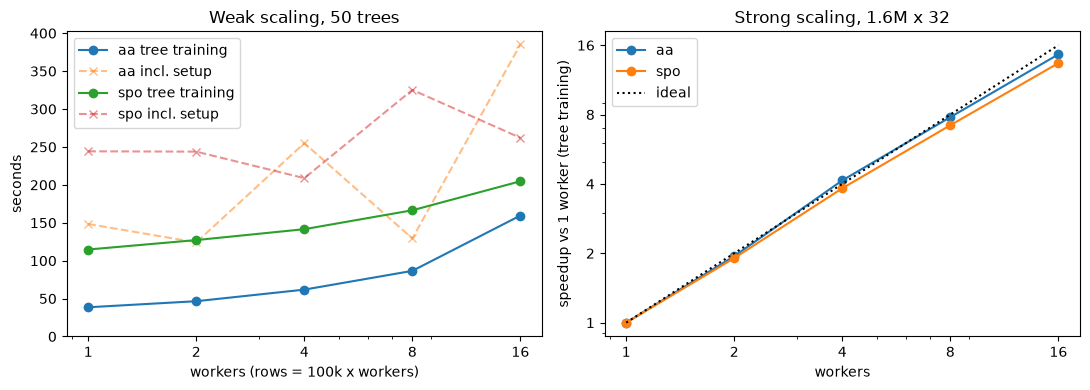

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for arm, g in weak.groupby("arm"):
    ax[0].plot(g.workers, g.tree_training_s, "o-", label=f"{arm} tree training")
    ax[0].plot(g.workers, g.train_seconds, "x--", alpha=.5, label=f"{arm} incl. setup")
ax[0].set(xscale="log", xlabel="workers (rows = 100k x workers)", ylabel="seconds", title="Weak scaling, 50 trees")
ax[0].set_xticks([1, 2, 4, 8, 16], [1, 2, 4, 8, 16]); ax[0].set_ylim(bottom=0); ax[0].legend()
for arm, g in strong.groupby("arm"):
    ax[1].plot(g.workers, g.speedup, "o-", label=arm)
ax[1].plot([1, 16], [1, 16], "k:", label="ideal")
ax[1].set(xscale="log", yscale="log", xlabel="workers", ylabel="speedup vs 1 worker (tree training)", title="Strong scaling, 1.6M x 32")
ax[1].set_xticks([1, 2, 4, 8, 16], [1, 2, 4, 8, 16]); ax[1].set_yticks([1, 2, 4, 8, 16], [1, 2, 4, 8, 16]); ax[1].legend()
fig.tight_layout()
fig.savefig(f"{out_dir}/scaling.png", dpi=130)
print("saved", f"{out_dir}/scaling.png")